In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx

# scratch space for creating script

In [52]:
struct_baselines = {
    'nnodes': lambda G: G.number_of_nodes(),
    'nedges': lambda G: G.number_of_edges(),
    'density': lambda G: nx.density(G),
    'nconn_components': lambda G: nx.number_connected_components(G),
    'avg_clustering': lambda G: nx.average_clustering(G),
    'avg_shortest_path': lambda G: np.mean([nx.average_shortest_path_length(G.subgraph(c).copy()) for c in nx.connected_components(G)]),
    'max_diameter': lambda G: np.max([nx.diameter(G.subgraph(c).copy()) for c in nx.connected_components(G)]),
    'deg_statistic': lambda G: sorted(list(dict(G.degree()).values())),
}

In [29]:
[nx.average_shortest_path_length(G.subgraph(c).copy()) for c in nx.connected_components(G)]

[0, 3.283333333333333, 0, 0, 0]

In [14]:
sorted(list(dict(G.degree()).values()))

[7, 7, 7, 7, 7, 7, 8, 8, 8, 9, 9, 9, 9, 9, 10, 11, 11, 11, 12, 12]

In [61]:
G_nx = [nx.erdos_renyi_graph(n=20, p=0.9) for i in range(100)] + [nx.erdos_renyi_graph(n=10, p=0.1) for i in range(100)]

In [62]:
arrays = []
for n_baseline in struct_baselines:
    if n_baseline != 'deg_statistic':
        array = np.array([struct_baselines[n_baseline](G_nx[i]) for i in range(len(G_nx))])
        array = array.reshape(-1,1)
        arrays.append(array)
    else:
        array = []
        for G in G_nx:
            padded_feature = np.pad(struct_baselines[n_baseline](G), (0, 30-len(struct_baselines[n_baseline](G))), constant_values=(0,0))
            array.append(padded_feature)
        array = np.array(array)
        arrays.append(array)

In [64]:
arrays[-1][0]

array([15, 15, 15, 15, 16, 16, 17, 17, 17, 17, 17, 17, 17, 18, 18, 18, 18,
       18, 18, 19,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0])

In [57]:
len(arrays[-1].shape)

2

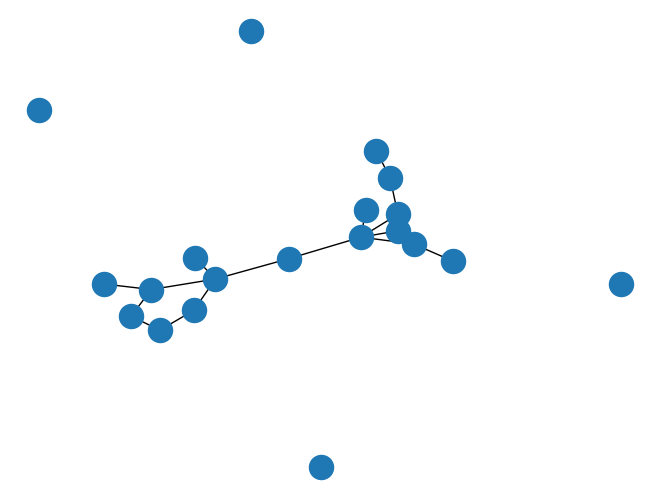

In [26]:
nx.draw(G)

# playground

In [49]:

from diversity_curves.simulate import simulate_graphs_kwargs

In [60]:
G_nx_model, Gs_model, y_model, y_probs_model, n_nodes_model = (
            simulate_graphs_kwargs(
                model='ER',
                n_graphs=3,
                nodes_range=range(10, 30, 1),
            )
)

In [61]:
G_nx_model2, Gs_model2, y_model2, y_probs_model2, n_nodes_model2 = (
            simulate_graphs_kwargs(
                model='ER',
                n_graphs=60,
                nodes_range=range(30, 31, 1),
            )
)

In [57]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
import argparse
import os
import random

from grakel import GraphKernel
from karateclub import NetLSD, Graph2Vec, FeatherGraph
import toper

from sklearn.manifold import MDS
from sklearn.decomposition import PCA

from magnipy.magnitude.distances import get_dist
from diversity_curves.process import get_mag_graphs, get_funs_df, get_mag_funs_graphs

from diversity_curves.simulate import simulate_graphs_kwargs
from diversity_curves.classifiers import knn_classifier
from diversity_curves.clustering_performance import (
    compute_clustering_scores_resample,
    compute_silhouette_score_resamples,
    compute_rand_agglo,
    compute_rand_kmeans,
    all_clustering_results_euclidean,
)
from diversity_curves.baselines.spectral_zoo import est_moment
from diversity_curves.baselines.ph import obtain_input_from_graphs

if True:
    np.random.seed(43)
    random.seed(314)

   
    # results_dir = args.output_dir
    n_low = 29
    n_high = 30
    n_steps = 1
    n_graphs = 60

    # Setting the parameters as reported in the paper
    model_params = {
        "ER": {
            "ER_probs": [0.75],
            "ER_nps": None,
        },
        "RPG": {
            "RPG_probs": [[0.9, 0.1]],
            "RPG_props": [1 / 3, 1 / 3],
        },
        "SBM": {"SBM_probs": [0.8, 0.05], "SBM_blocks": [[1 / 4, 1 / 4, 1 / 4]]},
        "RG": {"RG_probs": [0.25]},
    }

    # choice of graph metric we use for the spread computation
    graph_metrics = ["shortest_path_distance"]

    # get configuration of all models
    models = list(model_params.keys())
    all_configs = {}
    for model in models:
        model_config = tuple(
            model_params[model][param] for param in model_params[model].keys()
        )
        all_configs[model] = model_config
    configuration = tuple(all_configs[model] for model in models)

    noderange = range(n_low, n_high, n_steps)
    downsample_to = None

    scores = [
        "acc_mean",
        "silh_mean",
        "ari_agglo_mean",
        "db_mean",
        "ch_mean",
        "ari_kmeans_mean",
    ]
    scores_asc = {
        "acc_mean": False,
        "silh_mean": False,
        "ari_agglo_mean": False,
        "db_mean": True,
        "ch_mean": False,
        "ari_kmeans_mean": False,
    }

    res_dict = {}

    # if not os.path.exists(results_dir):
    #     os.makedirs(results_dir, exist_ok=True)

    # generate the graphs of all models and create label per model
    G_nx = []
    Gs = []
    n_nodes = []
    y_models = []
    class_labels = {}
    for i_m, model in enumerate(model_params):
        model_kwargs = model_params[model]
        print(f"model {model} kwargs {model_kwargs}")
        G_nx_model, Gs_model, y_model, y_probs_model, n_nodes_model = (
            simulate_graphs_kwargs(
                model=model,
                n_graphs=n_graphs,
                nodes_range=noderange,
                **model_kwargs,
            )
        )
        G_nx.extend(G_nx_model)
        Gs.extend(Gs_model)
        n_nodes.extend(n_nodes_model)
        y_models.extend([i_m] * len(G_nx_model))
        class_labels[i_m] = model

    upsample_to = max(n_nodes)
    y = y_models
    hue_names = [class_labels[i] for i in y]

    # setting parameters for plots
    sns.set_style("white")
    matplotlib.rcParams.update({"font.size": 20})

    ##################################
    ### computing diversity curves ###
    ##################################

    for metric in graph_metrics:

        res_dict[f"divcurves_{metric}"] = {}
        res_dict[f"divcurves_pca_{metric}"] = {}
        res_dict[f"div_function_{metric}"] = {}

        print(f"Computing MAG with metric: {metric}")

        def dist_fn(G):
            return get_dist(G=G, X=None, X2=None, metric=metric, mode="structure")

        all_spreads, weights_lists = get_mag_graphs(
            G_nx,
            dist_fn,
            ts=[1],
            upsample_to=upsample_to,
            downsample_to=downsample_to,
            n_repeats=3,
            scores_method='random',
            mode='structure',
            set_seed=False,
            compute_at_cardinality=list(range(1,30))
        )

        mag_funs = get_funs_df(all_spreads)
        mag_funs_interpolated = mag_funs.interpolate(method="linear", axis="columns")


model ER kwargs {'ER_probs': [0.75], 'ER_nps': None}
model RPG kwargs {'RPG_probs': [[0.9, 0.1]], 'RPG_props': [0.3333333333333333, 0.3333333333333333]}
model SBM kwargs {'SBM_probs': [0.8, 0.05], 'SBM_blocks': [[0.25, 0.25, 0.25]]}
model RG kwargs {'RG_probs': [0.25]}
Computing MAG with metric: shortest_path_distance


In [68]:
mag_funs_interpolated

index,1,2,3,4,5,6,7,8,9,10,...,20,21,22,23,24,25,26,27,28,29
graph,,,,,,,,,,,,,,,,,,,,,
0,1.0,1.462117,1.728351,1.901468,2.023048,2.113125,2.182537,2.237665,2.282505,2.319693,...,2.690906,2.712491,2.740318,2.778729,2.803973,2.863455,2.905724,2.951443,2.980046,3.012567
1,1.0,1.462117,1.728351,1.901468,2.023048,2.113125,2.182537,2.237665,2.282505,2.328511,...,2.689200,2.714248,2.755125,2.788814,2.833203,2.859687,2.900218,2.936699,2.972457,3.006852
2,1.0,1.462117,1.728351,1.901468,2.023048,2.113125,2.182537,2.237665,2.293102,2.337862,...,2.664138,2.714530,2.751994,2.785915,2.818385,2.856710,2.906446,2.942202,2.984872,3.011497
3,1.0,1.462117,1.728351,1.901468,2.023048,2.113125,2.182537,2.237665,2.282505,2.319693,...,2.689562,2.712450,2.752119,2.794712,2.829332,2.864686,2.901846,2.930413,2.968415,2.991536
4,1.0,1.462117,1.728351,1.901468,2.023048,2.113125,2.182537,2.237665,2.282505,2.319693,...,2.671950,2.700839,2.745087,2.802138,2.838298,2.858050,2.896522,2.925527,2.972455,3.002562
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,1.0,1.462117,1.799650,2.188249,2.423620,2.677905,2.893436,3.089141,3.254945,3.524992,...,5.430339,5.563718,5.810350,5.942805,6.022140,6.204033,6.291472,6.453776,6.694005,6.780496
236,1.0,2.000000,3.000000,3.462117,3.906599,4.215235,4.465529,4.776075,4.965023,5.320649,...,7.695443,7.856590,8.070577,8.320163,8.596844,8.828971,8.984022,9.072397,9.276171,9.407228
237,1.0,2.000000,2.462117,2.906599,3.296101,3.547000,3.934338,4.153599,4.211955,4.434322,...,6.902866,7.239021,7.634207,7.888654,8.113484,8.289132,8.506870,8.798930,9.045305,9.133936


In [74]:
len(noderange)

1

In [71]:
test_accs = knn_classifier(
                np.array(mag_funs_interpolated), np.array(y), precomputed=False
            )

Fold 0: test accuracy = 1.0000 (k=5)
Fold 1: test accuracy = 1.0000 (k=5)
Fold 2: test accuracy = 1.0000 (k=5)
Fold 3: test accuracy = 1.0000 (k=5)
Fold 4: test accuracy = 0.9583 (k=5)
Fold 5: test accuracy = 1.0000 (k=5)
Fold 6: test accuracy = 0.9583 (k=5)
Fold 7: test accuracy = 1.0000 (k=5)
Fold 8: test accuracy = 1.0000 (k=5)
Fold 9: test accuracy = 1.0000 (k=5)

Mean test accuracy: 0.9917
Std test accuracy:  0.0167


In [70]:
np.array(mag_funs_interpolated)

array([[1.        , 1.46211716, 1.72835065, ..., 2.95144331, 2.98004626,
        3.01256706],
       [1.        , 1.46211716, 1.72835065, ..., 2.93669912, 2.9724566 ,
        3.00685247],
       [1.        , 1.46211716, 1.72835065, ..., 2.94220198, 2.98487155,
        3.01149725],
       ...,
       [1.        , 2.        , 2.46211716, ..., 8.79892998, 9.04530514,
        9.13393622],
       [1.        , 2.        , 2.46211716, ..., 9.52649268, 9.69269816,
        9.77816164],
       [1.        , 2.        , 2.46211716, ..., 8.11718001, 8.38448701,
        8.47581631]])

In [62]:
len(G_nx_model)

180

In [63]:
len(G_nx_model2)

180

In [ ]:
def binned_norm_spectra(G):
    norm_spectra = nx.normalized_laplacian_spectrum(G)
    norm_spectra[norm_spectra<0] = 0
    norm_spectra[norm_spectra>2] = 2
    hist, edges = np.histogram(norm_spectra, 20, range=(0,2))
    return hist

In [42]:
G_10 = nx.erdos_renyi_graph(30,0.1)
G_10.add_edge(0,3)
G_10.add_edge(0,4)
# G_10.add_edge(4,3)
norm_spect = nx.normalized_laplacian_spectrum(G_10)

In [44]:
norm_spect[norm_spect<0]= 0
norm_spect[norm_spect>2]= 2

In [45]:
norm_spect

array([0.00000000e+00, 4.50343642e-18, 1.48441107e-16, 1.75541349e-01,
       2.41213540e-01, 3.13124969e-01, 3.50950110e-01, 4.42571940e-01,
       5.05545867e-01, 5.48136046e-01, 6.45072214e-01, 6.88946840e-01,
       7.70677191e-01, 8.86802209e-01, 9.53854870e-01, 9.73860884e-01,
       1.02614984e+00, 1.09760478e+00, 1.21261697e+00, 1.27137251e+00,
       1.33503058e+00, 1.35130692e+00, 1.41389417e+00, 1.47770375e+00,
       1.56355038e+00, 1.66374304e+00, 1.67568862e+00, 1.76166997e+00,
       1.79886620e+00, 1.85450425e+00])

In [37]:
[ev for ev in norm_spect if ev < 0.1]

[0.0]

In [43]:
nx.number_connected_components(G_10)

3

In [46]:
np.histogram(norm_spect, 20, range=(0,2))

(array([3, 1, 1, 2, 1, 2, 2, 1, 1, 2, 2, 0, 2, 2, 2, 1, 2, 2, 1, 0]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1, 1.2,
        1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. ]))

# Results
## generating table

In [4]:
# getting the right parameters
model_params = {
        'ER': {'ER_probs': [0.75], 
                'ER_nps': None,
        },
        'RPG':{
            'RPG_probs': [[0.9, 0.1]], 
            'RPG_props': [1/3, 1/3], 
        },
        'SBM': {
            'SBM_probs': [0.8, 0.05], 
            'SBM_blocks': [[1/4, 1/4, 1/4]]
            },
        'RG': {
            'RG_probs': [0.25]
        },
    }
    
models = list(model_params.keys())
all_configs = {}
for model in models:
    model_config = tuple(model_params[model][param] for param in model_params[model].keys())
    all_configs[model] = model_config
configuration = tuple(all_configs[model] for model in models)

# read dataframe
res_df = pd.read_csv(f'simulations/results/sim_distributions/struct_baseline/res_df.csv', header=0, index_col=0)


# group methods
method_group = {}
for method in list(res_df.index):
    if 'structure_baseline' in method:
        method_group[method] = 'Baseline'
    elif 'divcurves' in method:
        method_group[method] = 'Diversity Curves'

      
res_df['group'] = [method_group[method] for method in list(res_df.index)]

#rename rows, only relevant ones, rest will be dropped
new_names = {
        'divcurves_shortest_path_distance': 'Shortest Path',
        'divcurves_pca_shortest_path_distance': 'Shortest Path PCA',
        'structure_baseline_nnodes': 'Number of Nodes',
        'structure_baseline_nedges': 'Number of Edges',
        # 'structure_baseline_density': 'Density',
        'structure_baseline_nconn_components': 'Number of Connected Components',
        'structure_baseline_avg_clustering': 'Clustering Coefficient',
        'structure_baseline_avg_shortest_path': 'Average Shortest Path',
        'structure_baseline_max_diameter': 'Max Diameter',
        'structure_baseline_deg_statistic': 'Degree Sequence',
        'structure_baseline_summary': 'Summary Statistic',
        # 'structure_baseline_laplacian_spectrum_pad': 'Laplacian Spectrum (padded)',
        'structure_baseline_laplacian_spectrum_bin': 'Laplacian Spectrum (binned)',
}

df = res_df.rename(new_names)
df = df.loc[list(new_names.values()),:]

# add group to multiindex
df = df.set_index('group', append = True).swaplevel(0,1)
df.index.rename(['Group', 'Method'], inplace = True)

# sort wrt to accuracy, in groups
df = df.groupby(level=0, sort=False).apply(lambda x: x.sort_values('acc_mean', ascending=False)).droplevel(0)

scores = ['acc', 'silh', 'db', 'ch', 'ari_kmeans', 'ari_agglo']
scores_asc = {'acc': False, 'silh': False, 'ari_agglo': False, 'db': True,'ch': False, 'ari_kmeans': False}

res_copy = df.copy()

results_latex = {}

for score in scores:
   mean_col = f'{score}_mean'
   std_col = f'{score}_std'

   if mean_col in res_copy.columns and std_col in res_copy.columns:
      results_latex[score] = res_copy[mean_col].combine(
            res_copy[std_col],
            lambda m, s: '{:.3f}'.format(round(m, 3)) + ' $\pm $ ' + '{:.3f}'.format(round(s, 3))
      )

results_latex_df = pd.DataFrame.from_dict(results_latex)

# Bold the best mean for each score 
for score in scores:
   mean_col = f"{score}_mean"
   display_col =  score
   if mean_col in res_copy.columns:
      if not scores_asc[score]: 
            best_mask = round(res_copy[mean_col],3) == round(res_copy[mean_col].max(),3)
      else:
            best_mask = round(res_copy[mean_col],3) == round(res_copy[mean_col].min(),3)
      results_latex_df.loc[best_mask, display_col] = results_latex_df.loc[best_mask, display_col].apply(
            lambda x: f"\\textbf{{{x}}}"
      )
   else:
      print(f'{mean_col} not in dataframe?')

#final adjustments latex df 
results_latex_df.index.rename([None, 'Method'], inplace = True)
new_cols = {
   'acc': 'Accuracy', 
   'silh': 'Silhouette Score', 
   'db': 'Davies-Bouldin', 
   'ch': 'Calinski-Harabasz', 
   'ari_kmeans': 'ARI k-means', 
   'ari_agglo': 'ARI agglomerative'
}

results_latex_df = results_latex_df.rename(columns=new_cols)
results_latex_df.replace(to_replace='nan $\\pm $ nan', value='-', inplace=True)

print(configuration)
print(results_latex_df.to_latex(multirow=False, escape=False))

(([0.75], None), ([[0.9, 0.1]], [0.3333333333333333, 0.3333333333333333]), ([0.8, 0.05], [[0.25, 0.25, 0.25]]), ([0.25],))
\begin{tabular}{llllllll}
\toprule
         &                 &                     Accuracy &             Silhouette Score &               Davies-Bouldin &               Calinski-Harabasz &                  ARI k-means &            ARI agglomerative \\
{} & Method &                              &                              &                              &                                 &                              &                              \\
\midrule
Diversity Curves & Shortest Path &  \textbf{0.904 $\pm $ 0.042} &           0.427 $\pm $ 0.034 &           0.748 $\pm $ 0.060 &           194.340 $\pm $ 34.081 &  \textbf{0.511 $\pm $ 0.081} &           0.311 $\pm $ 0.119 \\
         & Shortest Path PCA &           0.888 $\pm $ 0.053 &  \textbf{0.436 $\pm $ 0.034} &  \textbf{0.732 $\pm $ 0.060} &  \textbf{197.355 $\pm $ 35.008} &  \textbf{0.511 $\pm $ 0.080

In [5]:
df

silh_mean    db_mean  \
Group            Method                                                 
Diversity Curves Shortest Path                    0.426791   0.748132   
                 Shortest Path PCA                0.435842   0.732327   
Baseline         Summary Statistic               -0.053127   3.196425   
                 Laplacian Spectrum (binned)      0.058401   2.784991   
                 Degree Sequence                 -0.027648   3.459280   
                 Average Shortest Path            0.187360  23.435316   
                 Clustering Coefficient           0.041178   4.252141   
                 Max Diameter                     0.243374  15.235276   
                 Number of Edges                 -0.093871   3.665604   
                 Number of Connected Components  -0.133582   1.712764   
                 Number of Nodes                 -0.083137  99.298258   

                                                    ch_mean  silh_std  \
Group            Method                                                 
Diversity Curves Shortest Path                   194.340472  0.033794   
                 Shortest Path PCA               197.354888  0.034473   
Baseline         Summary Statistic                31.287477  0.016859   
                 Laplacian Spectrum (binned)      20.416965  0.011334   
                 Degree Sequence                  23.816692  0.011766   
                 Average Shortest Path            30.408874  0.040305   
                 Clustering Coefficient           34.702434  0.030873   
                 Max Diameter                     33.867329  0.043274   
                 Number of Edges                  33.508424  0.021170   
                 Number of Connected Components   68.197326  0.055083   
                 Number of Nodes                   0.531599  0.012990   

                                                     db_std     ch_std  \
Group            Method                                                  
Diversity Curves Shortest Path                     0.059847  34.081011   
                 Shortest Path PCA                 0.059935  35.007875   
Baseline         Summary Statistic                 0.640184   5.295769   
                 Laplacian Spectrum (binned)       0.236895   2.458492   
                 Degree Sequence                   0.308473   3.309646   
                 Average Shortest Path            90.533981   7.871319   
                 Clustering Coefficient            4.872266   5.472647   
                 Max Diameter                     31.362354   6.923131   
                 Number of Edges                   2.337651   5.866155   
                 Number of Connected Components    0.408686  14.380464   
                 Number of Nodes                 196.612996   0.473977   

                                                 ari_agglo_mean  \
Group            Method                                           
Diversity Curves Shortest Path                         0.310997   
                 Shortest Path PCA                     0.317161   
Baseline         Summary Statistic                     0.090128   
                 Laplacian Spectrum (binned)           0.149682   
                 Degree Sequence                       0.091037   
                 Average Shortest Path                 0.305089   
                 Clustering Coefficient                0.129107   
                 Max Diameter                          0.169143   
                 Number of Edges                       0.088511   
                 Number of Connected Components        0.185879   
                 Number of Nodes                      -0.011531   

                                                 ari_agglo_std  \
Group            Method                                          
Diversity Curves Shortest Path                        0.119196   
                 Shortest Path PCA                    0.122657   
Baseline         Summary Statistic                

In [3]:
# getting the right parameters
model_params = {
        'ER': {'ER_probs': [0.75], 
                'ER_nps': None,
        },
        'RPG':{
            'RPG_probs': [[0.9, 0.1]], 
            'RPG_props': [1/3, 1/3], 
        },
        'SBM': {
            'SBM_probs': [0.8, 0.05], 
            'SBM_blocks': [[1/4, 1/4, 1/4]]
            },
        'RG': {
            'RG_probs': [0.25]
        },
    }
    
models = list(model_params.keys())
all_configs = {}
for model in models:
    model_config = tuple(model_params[model][param] for param in model_params[model].keys())
    all_configs[model] = model_config
configuration = tuple(all_configs[model] for model in models)

# read dataframe
res_df = pd.read_csv(f'simulations/results/sim_distributions/set_seed_False/res_df.csv', header=0, index_col=0)


# group methods
method_group = {}
for method in list(res_df.index):
    if 'structure_baseline' in method:
        method_group[method] = 'Baseline'
    elif 'divcurves' in method:
        method_group[method] = 'Diversity Curves'

      
res_df['group'] = [method_group[method] for method in list(res_df.index)]

#rename rows, only relevant ones, rest will be dropped
new_names = {
        'divcurves_shortest_path_distance': 'Shortest Path',
        'divcurves_pca_shortest_path_distance': 'Shortest Path PCA',
        'structure_baseline_nnodes': 'Number of Nodes',
        'structure_baseline_nedges': 'Number of Edges',
        # 'structure_baseline_density': 'Density',
        'structure_baseline_nconn_components': 'Number of Connected Components',
        'structure_baseline_avg_clustering': 'Clustering Coefficient',
        'structure_baseline_avg_shortest_path': 'Average Shortest Path',
        'structure_baseline_max_diameter': 'Max Diameter',
        'structure_baseline_deg_statistic': 'Degree Sequence',
        'structure_baseline_summary': 'Summary Statistic',
        # 'structure_baseline_laplacian_spectrum_pad': 'Laplacian Spectrum (padded)',
        'structure_baseline_laplacian_spectrum_bin': 'Laplacian Spectrum (binned)',
}

df = res_df.rename(new_names)
df = df.loc[list(new_names.values()),:]

# add group to multiindex
df = df.set_index('group', append = True).swaplevel(0,1)
df.index.rename(['Group', 'Method'], inplace = True)

# sort wrt to accuracy, in groups
df = df.groupby(level=0, sort=False).apply(lambda x: x.sort_values('acc_mean', ascending=False)).droplevel(0)

scores = ['acc', 'silh', 'db', 'ch', 'ari_kmeans', 'ari_agglo']
scores_asc = {'acc': False, 'silh': False, 'ari_agglo': False, 'db': True,'ch': False, 'ari_kmeans': False}

res_copy = df.copy()

results_latex = {}

for score in scores:
   mean_col = f'{score}_mean'
   std_col = f'{score}_std'

   if mean_col in res_copy.columns and std_col in res_copy.columns:
      results_latex[score] = res_copy[mean_col].combine(
            res_copy[std_col],
            lambda m, s: '{:.3f}'.format(round(m, 3)) + ' $\pm $ ' + '{:.3f}'.format(round(s, 3))
      )

results_latex_df = pd.DataFrame.from_dict(results_latex)

# Bold the best mean for each score 
for score in scores:
   mean_col = f"{score}_mean"
   display_col =  score
   if mean_col in res_copy.columns:
      if not scores_asc[score]: 
            best_mask = round(res_copy[mean_col],3) == round(res_copy[mean_col].max(),3)
      else:
            best_mask = round(res_copy[mean_col],3) == round(res_copy[mean_col].min(),3)
      results_latex_df.loc[best_mask, display_col] = results_latex_df.loc[best_mask, display_col].apply(
            lambda x: f"\\textbf{{{x}}}"
      )
   else:
      print(f'{mean_col} not in dataframe?')

#final adjustments latex df 
results_latex_df.index.rename([None, 'Method'], inplace = True)
new_cols = {
   'acc': 'Accuracy', 
   'silh': 'Silhouette Score', 
   'db': 'Davies-Bouldin', 
   'ch': 'Calinski-Harabasz', 
   'ari_kmeans': 'ARI k-means', 
   'ari_agglo': 'ARI agglomerative'
}

results_latex_df = results_latex_df.rename(columns=new_cols)
results_latex_df.replace(to_replace='nan $\\pm $ nan', value='-', inplace=True)

print(configuration)
print(results_latex_df.to_latex(multirow=False, escape=False))

(([0.75], None), ([[0.9, 0.1]], [0.3333333333333333, 0.3333333333333333]), ([0.8, 0.05], [[0.25, 0.25, 0.25]]), ([0.25],))
\begin{tabular}{llllllll}
\toprule
         &                 &                     Accuracy &             Silhouette Score &               Davies-Bouldin &               Calinski-Harabasz &                  ARI k-means &            ARI agglomerative \\
{} & Method &                              &                              &                              &                                 &                              &                              \\
\midrule
Diversity Curves & Shortest Path &  \textbf{0.904 $\pm $ 0.042} &           0.430 $\pm $ 0.035 &           0.754 $\pm $ 0.065 &           194.137 $\pm $ 30.275 &           0.510 $\pm $ 0.073 &  \textbf{0.334 $\pm $ 0.130} \\
         & Shortest Path PCA &           0.888 $\pm $ 0.053 &  \textbf{0.436 $\pm $ 0.037} &  \textbf{0.737 $\pm $ 0.063} &  \textbf{201.301 $\pm $ 32.720} &  \textbf{0.521 $\pm $ 0.077

In [4]:
df

silh_mean     db_mean  \
Group            Method                                                  
Diversity Curves Shortest Path                    0.429698    0.753800   
                 Shortest Path PCA                0.436123    0.736616   
Baseline         Summary Statistic               -0.050274    3.154089   
                 Laplacian Spectrum (binned)      0.059874    2.818255   
                 Degree Sequence                 -0.026554    3.461949   
                 Average Shortest Path            0.184708   30.371269   
                 Clustering Coefficient           0.039399    4.827097   
                 Max Diameter                     0.244205   21.896558   
                 Number of Edges                 -0.089745   19.036929   
                 Number of Connected Components  -0.131175    2.371187   
                 Number of Nodes                 -0.081144  149.215306   

                                                    ch_mean  silh_std  \
Group            Method                                                 
Diversity Curves Shortest Path                   194.137202  0.035275   
                 Shortest Path PCA               201.301494  0.037490   
Baseline         Summary Statistic                32.564222  0.018350   
                 Laplacian Spectrum (binned)      20.907480  0.011536   
                 Degree Sequence                  24.583090  0.013758   
                 Average Shortest Path            31.309141  0.054730   
                 Clustering Coefficient           33.790226  0.028988   
                 Max Diameter                     34.310718  0.043278   
                 Number of Edges                  34.919934  0.021603   
                 Number of Connected Components   69.228001  0.051757   
                 Number of Nodes                   0.435406  0.015170   

                                                     db_std     ch_std  \
Group            Method                                                  
Diversity Curves Shortest Path                     0.064995  30.274993   
                 Shortest Path PCA                 0.063108  32.719758   
Baseline         Summary Statistic                 0.681201   6.695669   
                 Laplacian Spectrum (binned)       0.277477   2.532539   
                 Degree Sequence                   0.321199   4.195235   
                 Average Shortest Path           205.319628  10.733646   
                 Clustering Coefficient            7.976257   4.563705   
                 Max Diameter                     91.077016   5.720721   
                 Number of Edges                 155.276970   7.452882   
                 Number of Connected Components    5.861487  14.347320   
                 Number of Nodes                 323.434445   0.389504   

                                                 ari_agglo_mean  \
Group            Method                                           
Diversity Curves Shortest Path                         0.334199   
                 Shortest Path PCA                     0.326456   
Baseline         Summary Statistic                     0.092106   
                 Laplacian Spectrum (binned)           0.146209   
                 Degree Sequence                       0.090203   
                 Average Shortest Path                 0.310229   
                 Clustering Coefficient                0.120274   
                 Max Diameter                          0.170953   
                 Number of Edges                       0.085475   
                 Number of Connected Components        0.178773   
                 Number of Nodes                      -0.011630   

                                                 ari_agglo_std  \
Group            Method                                          
Diversity Curves Shortest Path                        0.129701   
                 Shortest Path PCA                    0.138001   
Baseline         Summary Statistic   

In [7]:
# getting the right parameters
model_params = {
        'ER': {'ER_probs': [0.75], 
                'ER_nps': None,
        },
        'RPG':{
            'RPG_probs': [[0.9, 0.1]], 
            'RPG_props': [1/3, 1/3], 
        },
        'SBM': {
            'SBM_probs': [0.8, 0.05], 
            'SBM_blocks': [[1/4, 1/4, 1/4]]
            },
        'RG': {
            'RG_probs': [0.25]
        },
    }
    
models = list(model_params.keys())
all_configs = {}
for model in models:
    model_config = tuple(model_params[model][param] for param in model_params[model].keys())
    all_configs[model] = model_config
configuration = tuple(all_configs[model] for model in models)

# read dataframe
res_df = pd.read_csv(f'simulations/results/sim_distributions/set_seed_TrueFalse/res_df.csv', header=0, index_col=0)


# group methods
method_group = {}
for method in list(res_df.index):
    if 'structure_baseline' in method:
        method_group[method] = 'Baseline'
    elif 'divcurves' in method:
        method_group[method] = 'Diversity Curves'

      
res_df['group'] = [method_group[method] for method in list(res_df.index)]

#rename rows, only relevant ones, rest will be dropped
new_names = {
        'divcurves_shortest_path_distance': 'Shortest Path',
        'divcurves_pca_shortest_path_distance': 'Shortest Path PCA',
        'structure_baseline_nnodes': 'Number of Nodes',
        'structure_baseline_nedges': 'Number of Edges',
        # 'structure_baseline_density': 'Density',
        'structure_baseline_nconn_components': 'Number of Connected Components',
        'structure_baseline_avg_clustering': 'Clustering Coefficient',
        'structure_baseline_avg_shortest_path': 'Average Shortest Path',
        'structure_baseline_max_diameter': 'Max Diameter',
        'structure_baseline_deg_statistic': 'Degree Sequence',
        'structure_baseline_summary': 'Summary Statistic',
        # 'structure_baseline_laplacian_spectrum_pad': 'Laplacian Spectrum (padded)',
        'structure_baseline_laplacian_spectrum_bin': 'Laplacian Spectrum (binned)',
}

df = res_df.rename(new_names)
df = df.loc[list(new_names.values()),:]

# add group to multiindex
df = df.set_index('group', append = True).swaplevel(0,1)
df.index.rename(['Group', 'Method'], inplace = True)

# sort wrt to accuracy, in groups
df = df.groupby(level=0, sort=False).apply(lambda x: x.sort_values('acc_mean', ascending=False)).droplevel(0)

scores = ['acc', 'silh', 'db', 'ch', 'ari_kmeans', 'ari_agglo']
scores_asc = {'acc': False, 'silh': False, 'ari_agglo': False, 'db': True,'ch': False, 'ari_kmeans': False}

res_copy = df.copy()

results_latex = {}

for score in scores:
   mean_col = f'{score}_mean'
   std_col = f'{score}_std'

   if mean_col in res_copy.columns and std_col in res_copy.columns:
      results_latex[score] = res_copy[mean_col].combine(
            res_copy[std_col],
            lambda m, s: '{:.3f}'.format(round(m, 3)) + ' $\pm $ ' + '{:.3f}'.format(round(s, 3))
      )

results_latex_df = pd.DataFrame.from_dict(results_latex)

# Bold the best mean for each score 
for score in scores:
   mean_col = f"{score}_mean"
   display_col =  score
   if mean_col in res_copy.columns:
      if not scores_asc[score]: 
            best_mask = round(res_copy[mean_col],3) == round(res_copy[mean_col].max(),3)
      else:
            best_mask = round(res_copy[mean_col],3) == round(res_copy[mean_col].min(),3)
      results_latex_df.loc[best_mask, display_col] = results_latex_df.loc[best_mask, display_col].apply(
            lambda x: f"\\textbf{{{x}}}"
      )
   else:
      print(f'{mean_col} not in dataframe?')

#final adjustments latex df 
results_latex_df.index.rename([None, 'Method'], inplace = True)
new_cols = {
   'acc': 'Accuracy', 
   'silh': 'Silhouette Score', 
   'db': 'Davies-Bouldin', 
   'ch': 'Calinski-Harabasz', 
   'ari_kmeans': 'ARI k-means', 
   'ari_agglo': 'ARI agglomerative'
}

results_latex_df = results_latex_df.rename(columns=new_cols)
results_latex_df.replace(to_replace='nan $\\pm $ nan', value='-', inplace=True)

print(configuration)
print(results_latex_df.to_latex(multirow=False, escape=False))

(([0.75], None), ([[0.9, 0.1]], [0.3333333333333333, 0.3333333333333333]), ([0.8, 0.05], [[0.25, 0.25, 0.25]]), ([0.25],))
\begin{tabular}{llllllll}
\toprule
         &                 &                     Accuracy &             Silhouette Score &               Davies-Bouldin &               Calinski-Harabasz &                  ARI k-means &            ARI agglomerative \\
{} & Method &                              &                              &                              &                                 &                              &                              \\
\midrule
Diversity Curves & Shortest Path &  \textbf{0.904 $\pm $ 0.059} &           0.426 $\pm $ 0.039 &           0.750 $\pm $ 0.064 &  \textbf{198.464 $\pm $ 36.689} &           0.505 $\pm $ 0.081 &           0.300 $\pm $ 0.106 \\
         & Shortest Path PCA &           0.892 $\pm $ 0.065 &  \textbf{0.433 $\pm $ 0.038} &  \textbf{0.741 $\pm $ 0.063} &           198.032 $\pm $ 31.519 &  \textbf{0.510 $\pm $ 0.078

In [9]:
df

silh_mean     db_mean  \
Group            Method                                                  
Diversity Curves Shortest Path                    0.426322    0.750161   
                 Shortest Path PCA                0.432778    0.740612   
Baseline         Summary Statistic               -0.050274    3.154089   
                 Laplacian Spectrum (binned)      0.059874    2.818255   
                 Degree Sequence                 -0.026554    3.461949   
                 Average Shortest Path            0.184708   30.371269   
                 Clustering Coefficient           0.039399    4.827097   
                 Max Diameter                     0.244205   21.896558   
                 Number of Edges                 -0.089745   19.036929   
                 Number of Connected Components  -0.131175    2.371187   
                 Number of Nodes                 -0.081144  149.215306   

                                                    ch_mean  silh_std  \
Group            Method                                                 
Diversity Curves Shortest Path                   198.463572  0.038849   
                 Shortest Path PCA               198.032245  0.037794   
Baseline         Summary Statistic                32.564222  0.018350   
                 Laplacian Spectrum (binned)      20.907480  0.011536   
                 Degree Sequence                  24.583090  0.013758   
                 Average Shortest Path            31.309141  0.054730   
                 Clustering Coefficient           33.790226  0.028988   
                 Max Diameter                     34.310718  0.043278   
                 Number of Edges                  34.919934  0.021603   
                 Number of Connected Components   69.228001  0.051757   
                 Number of Nodes                   0.435406  0.015170   

                                                     db_std     ch_std  \
Group            Method                                                  
Diversity Curves Shortest Path                     0.063813  36.688995   
                 Shortest Path PCA                 0.063115  31.518618   
Baseline         Summary Statistic                 0.681201   6.695669   
                 Laplacian Spectrum (binned)       0.277477   2.532539   
                 Degree Sequence                   0.321199   4.195235   
                 Average Shortest Path           205.319628  10.733646   
                 Clustering Coefficient            7.976257   4.563705   
                 Max Diameter                     91.077016   5.720721   
                 Number of Edges                 155.276970   7.452882   
                 Number of Connected Components    5.861487  14.347320   
                 Number of Nodes                 323.434445   0.389504   

                                                 ari_agglo_mean  \
Group            Method                                           
Diversity Curves Shortest Path                         0.300243   
                 Shortest Path PCA                     0.315015   
Baseline         Summary Statistic                     0.092106   
                 Laplacian Spectrum (binned)           0.146209   
                 Degree Sequence                       0.090203   
                 Average Shortest Path                 0.310229   
                 Clustering Coefficient                0.120274   
                 Max Diameter                          0.170953   
                 Number of Edges                       0.085475   
                 Number of Connected Components        0.178773   
                 Number of Nodes                      -0.011630   

                                                 ari_agglo_std  \
Group            Method                                          
Diversity Curves Shortest Path                        0.106127   
                 Shortest Path PCA                    0.124877   
Baseline         Summary Statistic   

In [10]:
# getting the right parameters
model_params = {
        'ER': {'ER_probs': [0.75], 
                'ER_nps': None,
        },
        'RPG':{
            'RPG_probs': [[0.9, 0.1]], 
            'RPG_props': [1/3, 1/3], 
        },
        'SBM': {
            'SBM_probs': [0.8, 0.05], 
            'SBM_blocks': [[1/4, 1/4, 1/4]]
            },
        'RG': {
            'RG_probs': [0.25]
        },
    }
    
models = list(model_params.keys())
all_configs = {}
for model in models:
    model_config = tuple(model_params[model][param] for param in model_params[model].keys())
    all_configs[model] = model_config
configuration = tuple(all_configs[model] for model in models)

# read dataframe
res_df = pd.read_csv(f'simulations/results/sim_distributions/set_seed_TrueTrue/res_df.csv', header=0, index_col=0)


# group methods
method_group = {}
for method in list(res_df.index):
    if 'structure_baseline' in method:
        method_group[method] = 'Baseline'
    elif 'divcurves' in method:
        method_group[method] = 'Diversity Curves'

      
res_df['group'] = [method_group[method] for method in list(res_df.index)]

#rename rows, only relevant ones, rest will be dropped
new_names = {
        'divcurves_shortest_path_distance': 'Shortest Path',
        'divcurves_pca_shortest_path_distance': 'Shortest Path PCA',
        'structure_baseline_nnodes': 'Number of Nodes',
        'structure_baseline_nedges': 'Number of Edges',
        # 'structure_baseline_density': 'Density',
        'structure_baseline_nconn_components': 'Number of Connected Components',
        'structure_baseline_avg_clustering': 'Clustering Coefficient',
        'structure_baseline_avg_shortest_path': 'Average Shortest Path',
        'structure_baseline_max_diameter': 'Max Diameter',
        'structure_baseline_deg_statistic': 'Degree Sequence',
        'structure_baseline_summary': 'Summary Statistic',
        # 'structure_baseline_laplacian_spectrum_pad': 'Laplacian Spectrum (padded)',
        'structure_baseline_laplacian_spectrum_bin': 'Laplacian Spectrum (binned)',
}

df = res_df.rename(new_names)
df = df.loc[list(new_names.values()),:]

# add group to multiindex
df = df.set_index('group', append = True).swaplevel(0,1)
df.index.rename(['Group', 'Method'], inplace = True)

# sort wrt to accuracy, in groups
df = df.groupby(level=0, sort=False).apply(lambda x: x.sort_values('acc_mean', ascending=False)).droplevel(0)

scores = ['acc', 'silh', 'db', 'ch', 'ari_kmeans', 'ari_agglo']
scores_asc = {'acc': False, 'silh': False, 'ari_agglo': False, 'db': True,'ch': False, 'ari_kmeans': False}

res_copy = df.copy()

results_latex = {}

for score in scores:
   mean_col = f'{score}_mean'
   std_col = f'{score}_std'

   if mean_col in res_copy.columns and std_col in res_copy.columns:
      results_latex[score] = res_copy[mean_col].combine(
            res_copy[std_col],
            lambda m, s: '{:.3f}'.format(round(m, 3)) + ' $\pm $ ' + '{:.3f}'.format(round(s, 3))
      )

results_latex_df = pd.DataFrame.from_dict(results_latex)

# Bold the best mean for each score 
for score in scores:
   mean_col = f"{score}_mean"
   display_col =  score
   if mean_col in res_copy.columns:
      if not scores_asc[score]: 
            best_mask = round(res_copy[mean_col],3) == round(res_copy[mean_col].max(),3)
      else:
            best_mask = round(res_copy[mean_col],3) == round(res_copy[mean_col].min(),3)
      results_latex_df.loc[best_mask, display_col] = results_latex_df.loc[best_mask, display_col].apply(
            lambda x: f"\\textbf{{{x}}}"
      )
   else:
      print(f'{mean_col} not in dataframe?')

#final adjustments latex df 
results_latex_df.index.rename([None, 'Method'], inplace = True)
new_cols = {
   'acc': 'Accuracy', 
   'silh': 'Silhouette Score', 
   'db': 'Davies-Bouldin', 
   'ch': 'Calinski-Harabasz', 
   'ari_kmeans': 'ARI k-means', 
   'ari_agglo': 'ARI agglomerative'
}

results_latex_df = results_latex_df.rename(columns=new_cols)
results_latex_df.replace(to_replace='nan $\\pm $ nan', value='-', inplace=True)

print(configuration)
print(results_latex_df.to_latex(multirow=False, escape=False))

(([0.75], None), ([[0.9, 0.1]], [0.3333333333333333, 0.3333333333333333]), ([0.8, 0.05], [[0.25, 0.25, 0.25]]), ([0.25],))
\begin{tabular}{llllllll}
\toprule
         &                 &                     Accuracy &             Silhouette Score &               Davies-Bouldin &               Calinski-Harabasz &                  ARI k-means &            ARI agglomerative \\
{} & Method &                              &                              &                              &                                 &                              &                              \\
\midrule
Diversity Curves & Shortest Path &  \textbf{0.904 $\pm $ 0.059} &           0.423 $\pm $ 0.034 &           0.753 $\pm $ 0.060 &           191.237 $\pm $ 33.144 &           0.495 $\pm $ 0.071 &           0.313 $\pm $ 0.111 \\
         & Shortest Path PCA &           0.892 $\pm $ 0.065 &  \textbf{0.432 $\pm $ 0.035} &  \textbf{0.737 $\pm $ 0.060} &  \textbf{194.064 $\pm $ 34.006} &  \textbf{0.500 $\pm $ 0.075

In [11]:
df

silh_mean    db_mean  \
Group            Method                                                 
Diversity Curves Shortest Path                    0.423251   0.753192   
                 Shortest Path PCA                0.432269   0.737331   
Baseline         Summary Statistic               -0.053127   3.196425   
                 Laplacian Spectrum (binned)      0.058401   2.784991   
                 Degree Sequence                 -0.027648   3.459280   
                 Average Shortest Path            0.187360  23.435316   
                 Clustering Coefficient           0.041178   4.252141   
                 Max Diameter                     0.243374  15.235276   
                 Number of Edges                 -0.093871   3.665604   
                 Number of Connected Components  -0.133582   1.712764   
                 Number of Nodes                 -0.083137  99.298258   

                                                    ch_mean  silh_std  \
Group            Method                                                 
Diversity Curves Shortest Path                   191.237028  0.034222   
                 Shortest Path PCA               194.064338  0.034860   
Baseline         Summary Statistic                31.287477  0.016859   
                 Laplacian Spectrum (binned)      20.416965  0.011334   
                 Degree Sequence                  23.816692  0.011766   
                 Average Shortest Path            30.408874  0.040305   
                 Clustering Coefficient           34.702434  0.030873   
                 Max Diameter                     33.867329  0.043274   
                 Number of Edges                  33.508424  0.021170   
                 Number of Connected Components   68.197326  0.055083   
                 Number of Nodes                   0.531599  0.012990   

                                                     db_std     ch_std  \
Group            Method                                                  
Diversity Curves Shortest Path                     0.060239  33.144341   
                 Shortest Path PCA                 0.060398  34.006214   
Baseline         Summary Statistic                 0.640184   5.295769   
                 Laplacian Spectrum (binned)       0.236895   2.458492   
                 Degree Sequence                   0.308473   3.309646   
                 Average Shortest Path            90.533981   7.871319   
                 Clustering Coefficient            4.872266   5.472647   
                 Max Diameter                     31.362354   6.923131   
                 Number of Edges                   2.337651   5.866155   
                 Number of Connected Components    0.408686  14.380464   
                 Number of Nodes                 196.612996   0.473977   

                                                 ari_agglo_mean  \
Group            Method                                           
Diversity Curves Shortest Path                         0.313095   
                 Shortest Path PCA                     0.322707   
Baseline         Summary Statistic                     0.090128   
                 Laplacian Spectrum (binned)           0.149682   
                 Degree Sequence                       0.091037   
                 Average Shortest Path                 0.305089   
                 Clustering Coefficient                0.129107   
                 Max Diameter                          0.169143   
                 Number of Edges                       0.088511   
                 Number of Connected Components        0.185879   
                 Number of Nodes                      -0.011531   

                                                 ari_agglo_std  \
Group            Method                                          
Diversity Curves Shortest Path                        0.110951   
                 Shortest Path PCA                    0.122983   
Baseline         Summary Statistic                